# Fáza 4 - Deep Learning

Hugo Foltin, Teodor Potančok

## Výber datasetu

Vybrali sme si Quest 1 (klasifikácia). Dataset ktorý na to používame je [Ecommerce classify the objects based on their text description](https://www.kaggle.com/datasets/saurabhshahane/ecommerce-text-classification). Cieľ je vytrénovať NLP model ktorý vie čo najlepšie rozdeliť produkty do 4 kategórii podľa ich popisu.

## 4.1A EDA a data preprocessing

Pre začiatok načítame dataset z CSV a zistíme základné štatistiky.

In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

data = pd.read_csv("data/ecommerceDataset.csv", header=0, names=["label", "text"])

data.describe()

,label,text
count,50424,50423
unique,4,27801
top,Household,Think & Grow Rich About the Author NAPOLEON HI...
freq,19312,30


Vidíme že dataset má skutočne 4 kategórie (rôzne hodnoty `label`). V atribúte `text` máme 27 000 duplikátov, čo vychádza na 55.1% zo všetkých záznamov. Najčastejšia hodnota `Think & Grow Rich...` sa opakuje 30 krát.

In [31]:
data["label"].unique()

<StringArray>
['Household', 'Books', 'Clothing & Accessories', 'Electronics']
Length: 4, dtype: str

In [32]:
top_texts = data["text"].value_counts().head(30)
top_texts.index = top_texts.index.str.slice(0, 80)
top_categories = top_texts
top_texts

text
Think & Grow Rich About the Author NAPOLEON HILL, born in Pound, Southwest Virgi    30
The Power of Your Subconscious Mind: Unlock Your Master Key to Success About the    29
HP 680 Original Ink Advantage Cartridge (Black) Colour:Black   Make the most of     26
Diverse Men's Formal Shirt Diverse is a western wear value brand for men. Our ra    23
Cubetek 2 in 1 Bluetooth Transmitter & Receiver Adapter V4.1, with Digital Optic    22
Philips BHS386 Kera Shine Straightener (Purple) This Philips hair straightener i    20
The 5 AM Club: Own Your Morning, Elevate Your Life Review A book that could chan    19
Littly Front Open Kids Thermal Top & Pyjama Set for Baby Boys & Baby Girls, Pack    19
CBSE Chemistry Chapterwise Solved Papers Class 12th About the Author An editoria    19
Omnimount -Oecms-Neoprene-Cable-Management Omnimount Neoprene cable management      19
India Meets India Aum Cum Steel Tongue Happy Drum Pan with Rubber Musical Mallet    19
Pedigree Puppy Dry Dog Food, Chicken &

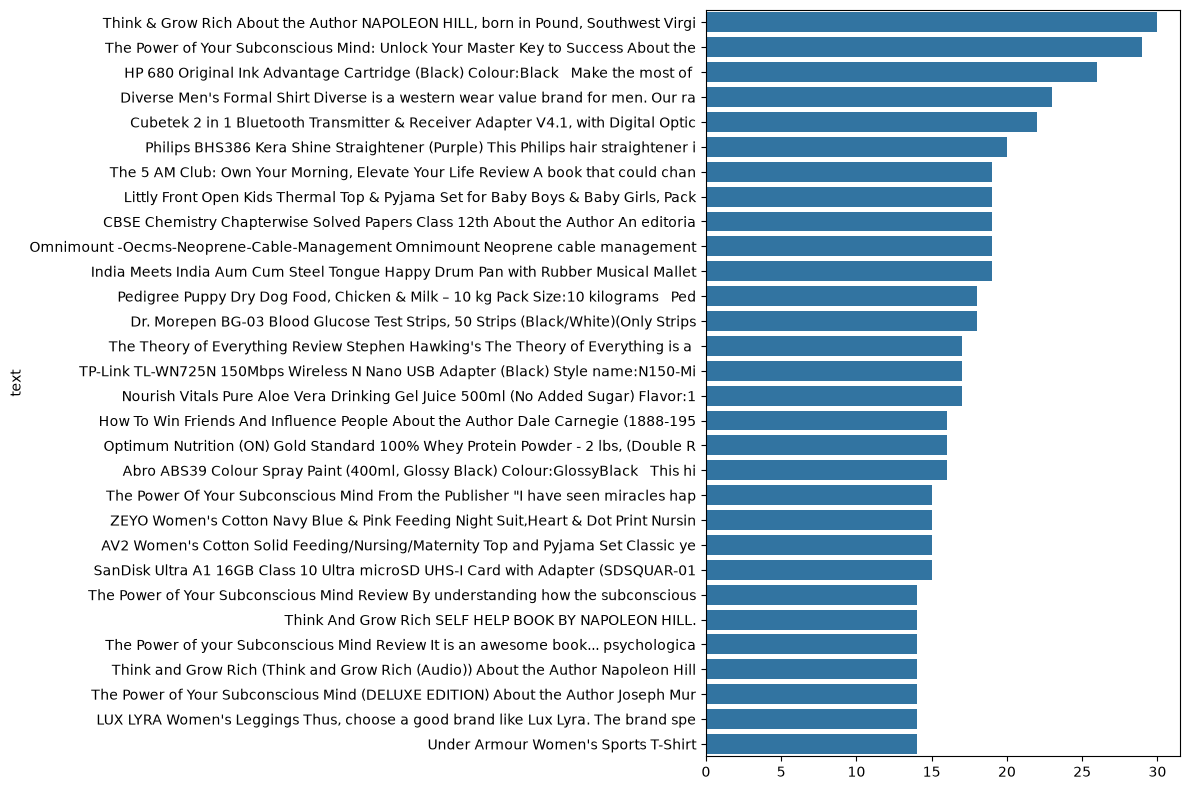

In [33]:
display_labels = top_texts.index.str.slice(0, 80)

plt.figure(figsize=(12, 8))
sns.barplot(x=top_texts.values, y=display_labels, errorbar=None)
plt.tight_layout()
plt.show()

Vyzerá že hlavný preprocessing ktorý potrebujeme je odstrániť duplikáty, aby sme predišli overfittingu alebo nekonzistentným zaradeniam (v prípade že niektorý produkt má v každom riadku inú kategóriu).

In [34]:
data = data.drop_duplicates(subset="text").reset_index(drop=True)

Okrem toho je dobré previesť všetko na malé písmená a odstrániť znaky ako `():'",.`, ktoré robia problémy pri tokenizácii - `(Black,` a `black` by sme mali brať ako rovnaký token.

In [ ]:
data["text"] = data["text"].str.lower().str.replace(r"[^a-zA-Z0-9\s]", " ", regex=True).str.strip()

data.head(10)

,label,text
0,Household,saf floral framed painting wood 30 inch x ...
1,Household,saf uv textured modern art print framed pain...
2,Household,saf flower print framed painting synthetic 1...
3,Household,incredible gifts india wooden happy birthday u...
4,Household,pitaara box romantic venice canvas painting 6m...


## 4.2B Výber ML metód

- RNN
- TF-IDF + SGD Classifier
- TF-IDF + Naive Bayes